# Lab 3 — Binary distillation and ideal stages

Design a teaching-model binary distillation column, using graphical stepping and a numerical stage counter. Explore the cost of demanding higher purity.

## Design workshop: run → compare → decide

All numerical methods, loops, tables and plots are supplied. You only change
values in cells marked **DESIGN SETTINGS** and write your engineering decisions.
In Colab, these settings also have parameter forms. The small worked examples
may be rerun after changing the named example values; their equations are supplied.
Run each analysis as provided; its implementation is collapsed where supported
and can be expanded if you are curious. No Python programming is assessed.

Work through the notebook in order. After changing an upstream setting, rerun
that section and every section below it so results stay consistent. Restore the
printed base values to reproduce the reference case. Keep at least one rejected
design and explain why you rejected it. Each analysis table is evidence for a
decision, not a complete answer on its own.

**Time budget (six hours):** setup and system prediction 30 min; balances and
feasibility 75 min; operating policy and checks 90 min; alternative designs
75 min; robustness and break 45 min; recommendation 45 min. The supplied
worked example belongs within the feasibility block, not an extra activity.

**Time budget: 6 hours, including a short break and submission.** Work in pairs,
but both partners must be able to explain every figure and calculation.
Prerequisites: material and energy balances, algebra, and reading tables and plots. No Python programming is required.
Use SI units unless explicitly stated. All case data are synthetic teaching values,
not measurements or validated equipment specifications.

Submit this notebook with outputs and a short engineering recommendation (300–500 words).
Include assumptions, a labelled flowsheet, equations, units, balance checks,
at least one sensitivity plot, and a discussion of model limitations.
Optional extensions are outside the six-hour budget.

## 1. Setup and prediction — 30 minutes
Before computing, sketch the apparatus and predict which parameter most strongly
affects its size or energy demand. Explain your reasoning in two sentences.

Locally, place `helpers.py` beside this notebook and install the root requirements.
In Colab, upload both files using the Files panel. Alternatively, after the repository
is published, set `HELPER_URL` below to the raw GitHub URL of this lab's `helpers.py`.
Use a commit SHA in the URL for reproducible teaching. Only download code from a
repository you trust. Each lab needs only its own helper file.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

HELPER_URL = ""  # e.g. https://raw.githubusercontent.com/OWNER/REPO/COMMIT/lab_01_flow/helpers.py
if not Path("helpers.py").exists():
    if not HELPER_URL:
        raise FileNotFoundError("Upload this lab's helpers.py or set HELPER_URL, then rerun.")
    urlretrieve(HELPER_URL, "helpers.py")

import numpy as np
import matplotlib.pyplot as plt
import helpers as h

## See the whole system

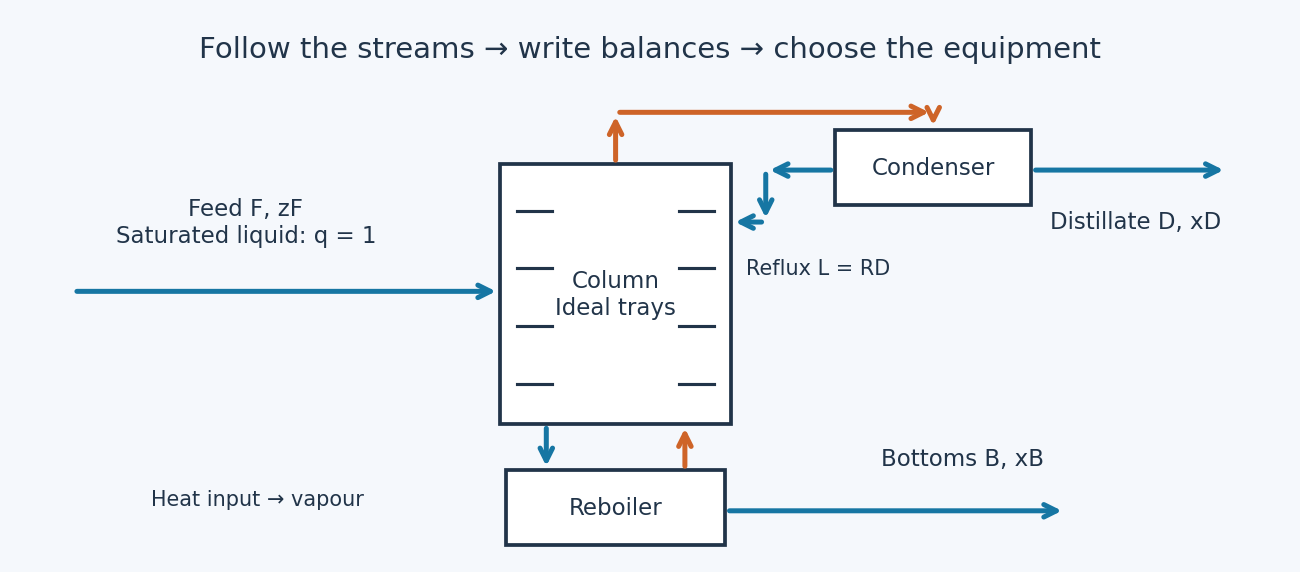

Schematic only: equipment sizes, heights and pipe lengths are not to scale.
Trace each stream with your finger. Identify what enters, what leaves, and where
energy is added or removed. Match the labels to the variables in the model below.

## Model and assumptions

Binary mixture, constant relative volatility $\alpha=2.4$, constant molar overflow,
saturated-liquid feed ($q=1$), total condenser and equilibrium partial reboiler.
These assumptions define a hypothetical mixture; they are not property data for a real pair.
$y^*(x)=\alpha x/[1+(\alpha-1)x]$.
Overall/component balances give $D=F(z_F-x_B)/(x_D-x_B)$ and $B=F-D$.
Rectifying line: $y=Rx/(R+1)+x_D/(R+1)$. For $q=1$ the feed line is vertical
at $x=z_F$. The stripping line joins the rectifying/feed intersection to $(x_B,x_B)$.
Starting at $(x_D,x_D)$, step horizontally to equilibrium and vertically to the
appropriate operating line. Use the rectifying line for $x\ge z_F$.
Count the final equilibrium step reaching $x\le x_B$ as one full stage (conservative
integer convention). This includes a partial reboiler and excludes the total condenser.

### Worked example: balances and the first two steps
The feed enters between the two column sections. A total condenser returns part
of the condensed overhead as reflux; the rest leaves as distillate. For a simple
case take F = 100 kmol/h, zF = 0.5, xD = 0.9, xB = 0.1 and R = 3.
The balances give D = B = 50 kmol/h. Start at y = xD, move to equilibrium
to find x, then use the rectifying operating line to obtain the next y.
This example stops after two steps; it is not a complete stage counter.

In [ ]:
ex_F, ex_zF, ex_xD, ex_xB, ex_R = 100.0, 0.5, 0.9, 0.1, 3.0
ex_D = ex_F * (ex_zF-ex_xB)/(ex_xD-ex_xB)
ex_B = ex_F - ex_D
print(f"Distillate = {ex_D:.1f}; bottoms = {ex_B:.1f} kmol/h")
ex_rect, ex_strip = h.operating_lines(ex_zF, ex_xD, ex_xB, ex_R)
ex_y = ex_xD
ex_points = [(ex_xD, ex_y)]
for ex_n in range(1, 3):
    ex_x = float(h.inverse_equilibrium(ex_y, 2.4))
    ex_points.append((ex_x, ex_y))  # horizontal: equilibrium
    ex_y = float(ex_rect(ex_x))  # both example steps are above the feed
    ex_points.append((ex_x, ex_y))  # vertical: operating line
    print(f"Step {ex_n}: liquid x = {ex_x:.4f}; next vapour y = {ex_y:.4f}")
ex_grid = np.linspace(0, 1, 200)
plt.figure(figsize=(6, 5))
plt.plot(ex_grid, h.equilibrium(ex_grid), label="Equilibrium")
plt.plot(ex_grid, ex_grid, color="grey", label="Diagonal")
plt.plot(ex_grid[ex_grid>=ex_zF], ex_rect(ex_grid[ex_grid>=ex_zF]), label="Rectifying")
ex_steps = np.array(ex_points)
plt.plot(ex_steps[:, 0], ex_steps[:, 1], "o-", label="First two stages")
plt.xlabel("Liquid mole fraction x"); plt.ylabel("Vapour mole fraction y")
plt.legend(); plt.grid(); plt.show()

**Try a small change:** Change R to 5 and compare the first two steps. The supplied main-case analysis switches to the stripping line when x < zF; identify where this happens. Explain why always using the rectifying line would fail below the feed.

Spend about 20 minutes on this example within the model-development time below. Predict → run → explain. Then move to the main case.

### Main design case

The next cell defines the larger case used in the assessed tasks. Example variables use `ex_` so you can rerun them without changing this case.

In [ ]:
F, zF, xD, xB, alpha = 100.0, 0.45, 0.95, 0.05, 2.4  # F in kmol/h
R = 2.5
x = np.linspace(0, 1, 400)
rect, strip = h.operating_lines(zF, xD, xB, R)
plt.plot(x, h.equilibrium(x, alpha), label="Equilibrium")
plt.plot(x, x, color="grey", label="Diagonal")
plt.plot(x[x>=zF], rect(x[x>=zF]), label="Rectifying")
plt.plot(x[x<=zF], strip(x[x<=zF]), label="Stripping")
plt.axvline(zF, linestyle=":", color="grey")
plt.xlabel("Liquid mole fraction x"); plt.ylabel("Vapour mole fraction y")
plt.legend(); plt.grid()

## 2. Establish the separation duty and reflux limit — 75 minutes

Run the supplied material balance and pinch construction. Check one
component balance with a calculator. Identify feed, reflux, distillate and
bottoms on the system diagram. Explain why the minimum reflux is a limit rather
than a usable finite-column design. Record the product flows and the minimum
reflux needed before considering equipment choices.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
D = F*(zF-xB)/(xD-xB)
B = F-D
total_residual = F-D-B
component_residual = F*zF-D*xD-B*xB
y_feed_star = float(h.equilibrium(zF,alpha))
pinch_slope = (xD-y_feed_star)/(xD-zF)
Rmin = pinch_slope/(1-pinch_slope)
assert np.isclose(total_residual,0)
assert np.isclose(component_residual,0)
assert np.isclose(Rmin,h.minimum_reflux(zF,xD,alpha))
print(f"D={D:.6f}; B={B:.6f} kmol/h")
print(f"Total residual={total_residual:.3e} kmol/h; light-component residual={component_residual:.3e} kmol/h")
print(f"Feed equilibrium y*={y_feed_star:.6f}; pinch slope={pinch_slope:.6f}; Rmin={Rmin:.6f}")
plt.figure(figsize=(6,5))
plt.plot(x,h.equilibrium(x,alpha),label='Equilibrium')
plt.plot(x,x,color='grey',label='Diagonal')
pinch_x = np.linspace(zF,xD,100)
plt.plot(pinch_x,pinch_slope*pinch_x+xD/(Rmin+1),label='Pinched rectifying line')
plt.scatter([zF,xD],[y_feed_star,xD],color='black')
plt.axvline(zF,color='grey',linestyle=':',label='q=1 feed line')
plt.xlabel('Liquid mole fraction x'); plt.ylabel('Vapour mole fraction y')
plt.legend(); plt.grid(); plt.show()

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 3. Choose a feasible reflux and inspect the column — 90 minutes

Choose a reflux ratio above the printed minimum. The supplied routine
draws the first three contacts and the complete staircase; do not write a stage
counter. Explain the horizontal and vertical moves using one printed pair of
coordinates. Locate the operating-line switch at the feed. Report ideal stages
and state whether the condenser and reboiler are included. Compare your reflux
choice with a higher one and describe the physical tradeoff.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# reflux ratio; must exceed Rmin (about 1.352 for the base case)
R = 2.5 #@param {type:"number"}

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
rect, strip = h.operating_lines(zF,xD,xB,R)
def distillation_steps(z, xd, xb, reflux, volatility=2.4, limit=300, inverse=None):
    if not 0 < xb < z < xd < 1 or volatility <= 1:
        raise ValueError("Invalid composition order or relative volatility")
    if inverse is None:
        if reflux <= h.minimum_reflux(z,xd,volatility):
            raise ValueError("Reflux at or below minimum")
        inverse = lambda y: float(h.inverse_equilibrium(y,volatility))
    elif reflux < 0:
        raise ValueError("Negative reflux")
    # Lines derived here independently of the helper's stage counter.
    def rectifying(x_value):
        return reflux/(reflux+1)*x_value+xd/(reflux+1)
    feed_y = rectifying(z)
    strip_slope = (feed_y-xb)/(z-xb)
    def stripping(x_value):
        return strip_slope*(x_value-xb)+xb
    previous_x, y_value = xd, xd
    staircase, contacts = [(xd,xd)], []
    for n in range(1,limit+1):
        x_value = float(inverse(y_value))
        if not 0 <= x_value < previous_x-1e-12:
            raise ValueError("Pinch, non-progress or composition outside physical bounds")
        staircase.append((x_value,y_value))
        section = 'rectifying' if x_value >= z else 'stripping'
        contacts.append((n,x_value,y_value,section))
        if x_value <= xb:
            return n,np.array(staircase),contacts
        y_value = rectifying(x_value) if x_value >= z else stripping(x_value)
        if not 0 <= y_value <= 1:
            raise ValueError("Operating line outside physical composition bounds")
        staircase.append((x_value,y_value))
        previous_x = x_value
    raise ValueError("Stage cap reached")

N_ideal, staircase, contacts = distillation_steps(zF,xD,xB,R,alpha)
assert N_ideal == h.stage_count(zF,xD,xB,R,alpha)[0]
feed_switch = next(row[0] for row in contacts if row[3]=='stripping')
print(f"Full ideal stages (partial reboiler included): {N_ideal}")
print(f"Operating-line switch after equilibrium contact {feed_switch}")
print("First three hand-checkable horizontal/vertical steps:")
print("n     liquid x     entering y    following line")
for n,liquid,vapour,section in contacts[:3]:
    print(f"{n}     {liquid:.6f}     {vapour:.6f}    {section}")
fig,axes = plt.subplots(1,2,figsize=(12,5))
for axis in axes:
    axis.plot(x,h.equilibrium(x,alpha),label='Equilibrium')
    axis.plot(x,x,color='grey',label='Diagonal')
    axis.plot(x[x>=zF],rect(x[x>=zF]),label='Rectifying')
    axis.plot(x[x<=zF],strip(x[x<=zF]),label='Stripping')
    axis.axvline(zF,color='grey',linestyle=':')
    axis.set(xlabel='Liquid mole fraction x',ylabel='Vapour mole fraction y')
    axis.grid()
# First three explicit steps can be checked from the printed coordinates.
axes[0].plot(staircase[:7,0],staircase[:7,1],'o-',color='black',label='First three steps')
axes[0].set_title('Graphical check'); axes[0].legend()
axes[1].plot(staircase[:,0],staircase[:,1],'o-',color='black',label='Full staircase')
axes[1].set_title('Complete numerical solution'); axes[1].legend()
plt.tight_layout(); plt.show()
# Explicit rejection check at the limiting reflux.
try:
    distillation_steps(zF,xD,xB,Rmin,alpha)
except ValueError as error:
    print('Expected infeasible case:',error)
else:
    raise AssertionError('Minimum reflux should be rejected')

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 4. Compare purity and operating policies — 75 minutes

Run the supplied reflux and purity comparisons. Select a preliminary
reflux policy and explain where extra reflux gives little stage reduction.
Does demanding 0.98 distillate purity appear worthwhile if the process only
requires 0.95? Use stage count, product flow and vapour load in your answer.
Explain why neither a minimum stage count nor a minimum vapour flow alone
identifies an economic optimum. List the cost and energy data needed to decide.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# R/Rmin; keep above 1
reflux_ratio_low = 1.1 #@param {type:"number"}
reflux_ratio_high = 3.0 #@param {type:"number"}
# mole fractions, above feed composition
purity_targets = [0.90, 0.95, 0.98] #@param {type:"raw"}
# compare each target at this R/Rmin
purity_reflux_multiple = 1.5 #@param {type:"number"}

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
ratios = np.linspace(reflux_ratio_low,reflux_ratio_high,60)
sweep = []
for ratio in ratios:
    candidate_R = ratio*Rmin
    try:
        stages = distillation_steps(zF,xD,xB,candidate_R,alpha)[0]
    except ValueError as error:
        print(f"R/Rmin={ratio:.3f}: infeasible or unresolved: {error}")
        stages = np.nan
    sweep.append((stages,(candidate_R+1)*D))
sweep = np.array(sweep)
fig,axes = plt.subplots(1,2,figsize=(11,4))
axes[0].step(ratios,sweep[:,0],where='mid'); axes[0].set_ylabel('Full ideal stages / count')
axes[1].plot(ratios,sweep[:,1]); axes[1].set_ylabel('Vapour load V / kmol h$^{-1}$')
for axis in axes:
    axis.set_xlabel('R / Rmin'); axis.grid()
plt.tight_layout(); plt.show()
print("xD     D/kmol h-1   B/kmol h-1   Rmin      R      stages    V/kmol h-1")
purity_results = []
for candidate_xD in purity_targets:
    candidate_D = F*(zF-xB)/(candidate_xD-xB)
    candidate_B = F-candidate_D
    candidate_min = h.minimum_reflux(zF,candidate_xD,alpha)
    candidate_R = purity_reflux_multiple*candidate_min
    candidate_N = distillation_steps(zF,candidate_xD,xB,candidate_R,alpha)[0]
    candidate_V = (candidate_R+1)*candidate_D
    purity_results.append((candidate_xD,candidate_D,candidate_B,candidate_min,candidate_R,candidate_N,candidate_V))
    assert np.isclose(candidate_D*candidate_xD+candidate_B*xB,F*zF)
    print(f"{candidate_xD:.2f}    {candidate_D:8.3f}      {candidate_B:8.3f}    {candidate_min:.4f}   {candidate_R:.4f}    {candidate_N:3d}      {candidate_V:8.3f}")

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 5. Translate ideal contacts into equipment — 45 minutes

Take a 10-minute break. Compare the supplied overall-efficiency cases.
Select an efficiency assumption for a preliminary tray-height estimate and
state what evidence would justify it. Explain the difference between overall
and Murphree efficiency. Distinguish active height from vessel height, including
at least three allowances absent from the model. Would efficiency uncertainty
change your preferred reflux policy?

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title DESIGN SETTINGS — edit values or use the Colab form
efficiency_cases = [0.50, 0.65, 0.80] #@param {type:"raw"}
selected_tray_efficiency = 0.65 #@param {type:"number"}
# m
tray_spacing = 0.45 #@param {type:"number"}

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
ideal_trays = N_ideal-1
tray_results = []
print("Overall efficiency   installed trays   active height / m")
for overall in efficiency_cases:
    actual = int(np.ceil(ideal_trays/overall))
    active_height = tray_spacing*actual
    tray_results.append((overall,actual,active_height))
    print(f"{overall:.2f}                  {actual:2d}                {active_height:.2f}")
selected_trays = int(np.ceil(ideal_trays/selected_tray_efficiency))
print(f"Selected assumption: {selected_trays} trays; active height={selected_trays*tray_spacing:.3f} m")

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 6. Engineering recommendation and submission — 45 minutes
Choose a design and support it with numbers. State what would need measuring before
using it in practice. Check your balances and inspect every axis label and unit.
Restart the kernel and run all completed cells in order before submission.

**Peer check:** Ask your partner to explain one equation, one numerical check,
and one reason the model could fail. Record any revision this discussion prompted.

**Design-review checklist:** Does your selected design meet every stated
requirement? Include its operating margin, one rejected alternative and a
numerical reason for rejection. Distinguish a model verification check from
evidence that real equipment will perform as predicted. Identify the next
measurement or vendor datum needed. No new code is required for submission.

## Optional design-review extension

No coding is required. What would you check before replacing the constant-volatility curve with measured equilibrium data? Explain the implications of interpolation uncertainty or an azeotrope.